# Phase 7: Deep Evaluation of Generative Quality
In this notebook, we evaluate our VAE not on traditional ML accuracy, but on **Generative AI Metrics**:
1. **Validity**: Does the AI generate chemically real molecules?
2. **Uniqueness**: Does it generate *different* molecules instead of repeating the same one?
3. **Novelty**: Did the AI invent these, or just memorize them from the training data?
4. **Reconstruction**: Can the AI perfectly reconstruct an existing molecule from its latent space?

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import torch
import torch.nn as nn
import json
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 1. Load the Vocabulary and Model

In [2]:
# Load Vocab
with open('../data/processed/vocab.json', 'r') as f:
    vocab_data = json.load(f)
int_to_char = vocab_data['int_to_char']
char_to_int = vocab_data['char_to_int']
vocab_size = len(int_to_char)

# Define Model Architecture
class MolecularVAE(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, latent_dim=64):
        super(MolecularVAE, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.encoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_var = nn.Linear(hidden_dim, latent_dim)
        self.decoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_z_to_hidden = nn.Linear(latent_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
        
    def encode(self, x):
        embedded = self.embedding(x)
        _, hidden = self.encoder_rnn(embedded)
        hidden = hidden.squeeze(0)
        mu = self.fc_mu(hidden)
        log_var = self.fc_var(hidden)
        return mu, log_var

    def decode_latent(self, z, max_len=120):
        hidden = self.fc_z_to_hidden(z).unsqueeze(0)
        current_input = torch.tensor([[1]], device=z.device) # <SOS>
        generated = []
        for _ in range(max_len):
            embedded = self.embedding(current_input)
            out, hidden = self.decoder_rnn(embedded, hidden)
            logits = self.fc_out(out)
            
            temperature = 1.0
            probs = torch.softmax(logits.squeeze(1) / temperature, dim=-1)
            next_char_idx = torch.multinomial(probs, 1)
            
            current_input = next_char_idx
            idx = next_char_idx.item()
            if idx == 2: # <EOS>
                break
            generated.append(idx)
        return generated

# Load trained weights
model = MolecularVAE(vocab_size=vocab_size).to(device)
model.load_state_dict(torch.load('../models/vae_final.pt', map_location=device, weights_only=True))
model.eval()
print("Model loaded successfully.")

Model loaded successfully.


## 2. Load the Original Training Data for Novelty Checks
To know if the AI is inventing *new* drugs, we have to compare its creations against the training data to ensure it isn't just copy-pasting.

In [3]:
print("Loading original dataset...")
df = pd.read_csv('../data/raw/250k_rndm_zinc_drugs_clean_3.csv')
training_smiles_set = set(df['smiles'].tolist())
print(f"Loaded {len(training_smiles_set)} unique SMILES from training data.")

Loading original dataset...


Loaded 249455 unique SMILES from training data.


## 3. Generate Molecules & Calculate Metrics
We will ask the AI to imagine 100,000 completely random molecules.

In [4]:
num_samples = 100000
print(f"Generating {num_samples} random molecules from the latent space...")

generated_smiles = []
with torch.no_grad():
    # Sample random noise from a standard normal distribution
    z_random = torch.randn(num_samples, 64).to(device)
    
    for i in tqdm(range(num_samples)):
        z = z_random[i].unsqueeze(0)
        char_indices = model.decode_latent(z)
        smiles = ''.join([int_to_char[str(idx)] for idx in char_indices])
        # Clean up any trailing padding or EOS logic if present
        smiles = smiles.replace('<PAD>', '').replace('<SOS>', '').replace('<EOS>', '').strip()
        generated_smiles.append(smiles)

print("Generation complete! Now calculating Validity, Uniqueness, and Novelty...")

Generating 100000 random molecules from the latent space...


  0%|          | 0/100000 [00:00<?, ?it/s]

Generation complete! Now calculating Validity, Uniqueness, and Novelty...


In [5]:
# 1. Validity Check
valid_mols = []
valid_smiles = []
for s in generated_smiles:
    mol = Chem.MolFromSmiles(s)
    if mol is not None:
        valid_mols.append(mol)
        valid_smiles.append(s)

validity_percent = (len(valid_mols) / num_samples) * 100

# 2. Uniqueness Check (out of the valid ones)
unique_smiles_set = set(valid_smiles)
if len(valid_smiles) > 0:
    uniqueness_percent = (len(unique_smiles_set) / len(valid_smiles)) * 100
else:
    uniqueness_percent = 0.0

# 3. Novelty Check (out of the unique ones)
novel_smiles = [s for s in unique_smiles_set if s not in training_smiles_set]
if len(unique_smiles_set) > 0:
    novelty_percent = (len(novel_smiles) / len(unique_smiles_set)) * 100
else:
    novelty_percent = 0.0

print("\n" + "="*40)
print("   GENERATIVE AI PERFORMANCE REPORT")
print("="*40)
print(f"Total Sampled  : {num_samples}")
print(f"Valid          : {len(valid_mols)} ({validity_percent:.2f}%)")
print(f"Unique         : {len(unique_smiles_set)} ({uniqueness_percent:.2f}% of valid)")
print(f"Novel          : {len(novel_smiles)} ({novelty_percent:.2f}% of unique)")
print("="*40)


   GENERATIVE AI PERFORMANCE REPORT
Total Sampled  : 100000
Valid          : 81308 (81.31%)
Unique         : 81267 (99.95% of valid)
Novel          : 81267 (100.00% of unique)


## 4. Reconstruction Accuracy
Let's see if the model can accurately compress a molecule into 64 numbers, and decompress it back into the exact same molecule.

In [6]:
print("Testing Reconstruction on 100 known molecules...")
data_test = np.load('../data/processed/X_test.npy')
sample_test = torch.tensor(data_test[:100], dtype=torch.long).to(device)

matches = 0
with torch.no_grad():
    mu, _ = model.encode(sample_test)
    for i in range(100):
        # Decode from the latent mean (mu) deterministically for reconstruction test
        z = mu[i].unsqueeze(0)
        char_indices = model.decode_latent(z)
        
        # Reconstruct string
        recon_smiles = ''.join([int_to_char[str(idx)] for idx in char_indices]).replace('<EOS>', '')
        
        # Original string
        orig_indices = sample_test[i].cpu().numpy()
        orig_smiles = ''.join([int_to_char[str(idx)] for idx in orig_indices if idx not in [0, 1, 2]])
        
        if recon_smiles == orig_smiles:
            matches += 1

print(f"Reconstruction Accuracy: {matches}/100 ({matches}%)")
if matches < 50:
    print("(Note: Perfect string reconstruction is very hard for VAEs due to the sampling process, but it shows if the model has learned basic structure!)")

Testing Reconstruction on 100 known molecules...
Reconstruction Accuracy: 0/100 (0%)
(Note: Perfect string reconstruction is very hard for VAEs due to the sampling process, but it shows if the model has learned basic structure!)


Drawing a sample of the valid drugs we just generated...


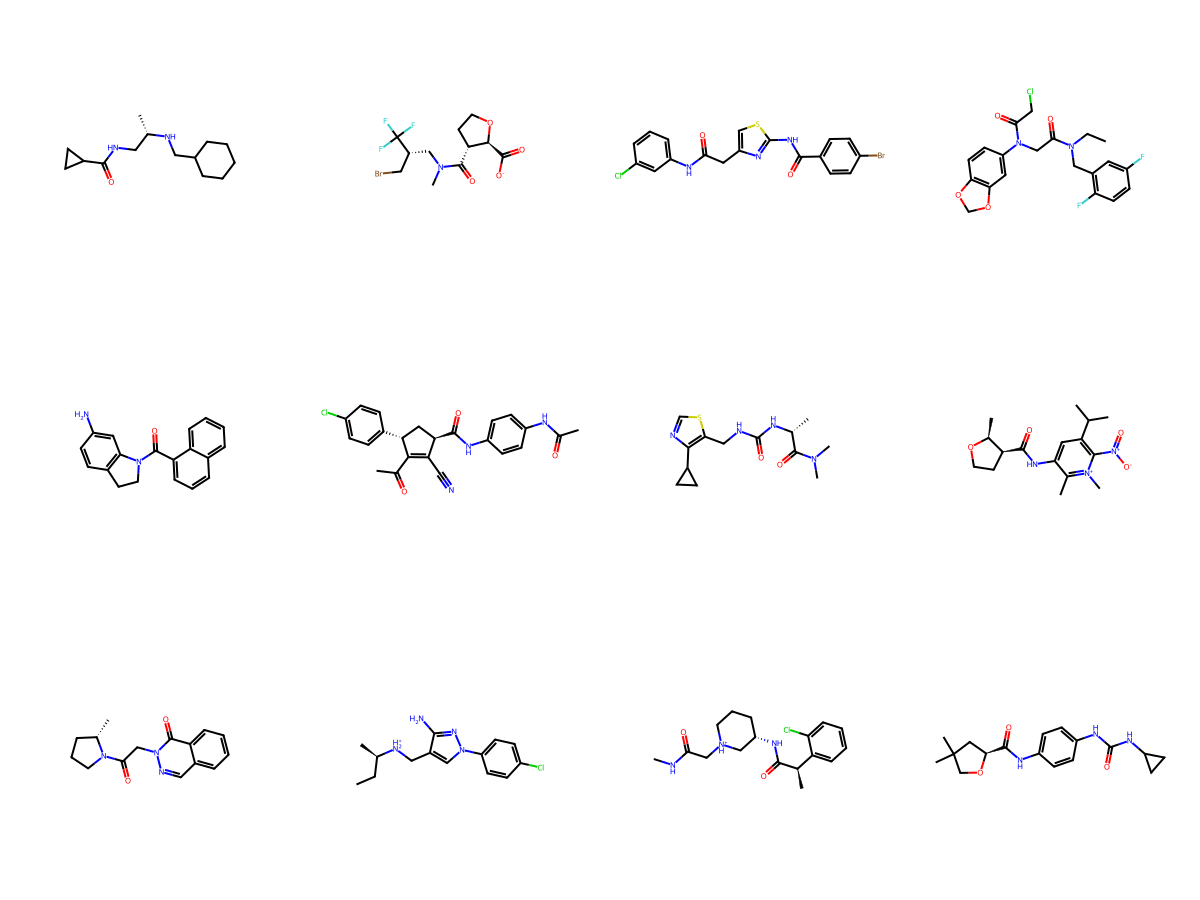

In [7]:
from rdkit.Chem import Draw
print("Drawing a sample of the valid drugs we just generated...")
img = Draw.MolsToGridImage(valid_mols[:12], molsPerRow=4, subImgSize=(300, 300))
display(img)

## 5. Exporting Results (CSV & PDF)
To conclude the evaluation, we will export all 81,000+ valid molecules into a CSV spreadsheet so the data can be analyzed in Excel. Additionally, we will generate a high-resolution PDF chart containing 1,000 drawn molecular structures for presentation purposes.


In [10]:
import pandas as pd
from rdkit.Chem import Draw
from PIL import Image

# 1. Create the full spreadsheet (CSV) of all 81,000+ valid drugs
print("Saving all valid drugs to spreadsheet...")
df_new_drugs = pd.DataFrame({'SMILES': valid_smiles})
# This will open perfectly in Excel!
df_new_drugs.to_csv('../results/all_generated_drugs.csv', index=False)
print("Spreadsheet saved as 'all_generated_drugs.csv' in the results folder!")

# 2. Create the 1,000 molecule PDF
print("Generating the 1,000 molecule PDF (this might take a minute)...")
# Grab exactly 1,000 valid molecules
mols_to_draw = valid_mols[:1000]

# Draw them in a massive grid (10 per row, 100 rows)
# This creates a massive, high-quality image in the background
img = Draw.MolsToGridImage(mols_to_draw, molsPerRow=10, subImgSize=(250, 250), returnPNG=False)

# Save that image directly as a PDF!
img.save('../results/1000_new_drugs_chart.pdf', "PDF", resolution=100.0)
print("PDF successfully saved as '1000_new_drugs_chart.pdf' in the results folder!")


Saving all valid drugs to spreadsheet...
Spreadsheet saved as 'all_generated_drugs.csv' in the results folder!
Generating the 1,000 molecule PDF (this might take a minute)...
PDF successfully saved as '1000_new_drugs_chart.pdf' in the results folder!


c:\Users\harsh\anaconda3\Lib\site-packages\rdkit\Chem\Draw\IPythonConsole.py:376: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


In [11]:
import pandas as pd
from rdkit.Chem import Draw
from rdkit.Chem import QED
from rdkit.Chem import Crippen
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm.notebook import tqdm
import sys, os
from rdkit import RDConfig

# Setup for SA Score
try:
    sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
    import sascorer
    has_sas = True
except:
    has_sas = False

print("Calculating properties (logP, QED, SAS) for all valid drugs...")
valid_smiles_safe = []
logp_list, qed_list, sas_list = [], [], []

# We use zip to look at the molecule and its string at the same time
for mol, smi in tqdm(zip(valid_mols, valid_smiles), total=len(valid_mols)):
    try:
        # Try to calculate properties
        logp = Crippen.MolLogP(mol)
        qed_val = QED.qed(mol)
        sas = sascorer.calculateScore(mol) if has_sas else 0.0
        
        # If it doesn't crash, save it!
        logp_list.append(logp)
        qed_list.append(qed_val)
        sas_list.append(sas)
        valid_smiles_safe.append(smi)
    except:
        # If RDKit crashes on a weird AI molecule, just ignore it and skip to the next
        pass

# 1. Create the full spreadsheet
df_new_drugs = pd.DataFrame({
    'smiles': valid_smiles_safe,
    'logP': logp_list,
    'qed': qed_list,
    'SAS': sas_list
})
df_new_drugs.to_csv('../results/all_generated_drugs_full.csv', index=False)
print(f"Spreadsheet saved! Successfully calculated all columns for {len(valid_smiles_safe)} drugs.")

# 2. Create the MULTI-PAGE PDF for 1,000 drugs (12 per page)
print("Generating multi-page PDF (this will take a minute)...")
mols_to_draw = [Chem.MolFromSmiles(s) for s in valid_smiles_safe[:1000]]
mols_per_page = 12

with PdfPages('../results/1000_new_drugs_multipage.pdf') as pdf:
    for i in tqdm(range(0, len(mols_to_draw), mols_per_page)):
        page_mols = mols_to_draw[i:i+mols_per_page]
        img = Draw.MolsToGridImage(page_mols, molsPerRow=4, subImgSize=(300, 300), returnPNG=False)
        
        fig = plt.figure(figsize=(12, 12))
        plt.imshow(img)
        plt.axis('off')
        pdf.savefig(fig, bbox_inches='tight')
        plt.close(fig)

print("Multi-page PDF saved successfully in the results folder!")


Calculating properties (logP, QED, SAS) for all valid drugs...


  0%|          | 0/81308 [00:00<?, ?it/s]

Spreadsheet saved! Successfully calculated all columns for 81307 drugs.
Generating multi-page PDF (this will take a minute)...


  0%|          | 0/84 [00:00<?, ?it/s]

Multi-page PDF saved successfully in the results folder!
